In [1]:
# Cell 1: Environment setup and initial data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.fft
import lightgbm as lgb
import joblib

# Load telemetry data
telemetry_path = r"C:\Users\aseem\Downloads\cpu_utilization_asg_misconfiguration.csv"
df_telemetry = pd.read_csv(telemetry_path)

# Quick parse and validation
df_telemetry['timestamp'] = pd.to_datetime(df_telemetry['timestamp'])
df_telemetry = df_telemetry.sort_values('timestamp').reset_index(drop=True)

print("Shape:", df_telemetry.shape)
print("\nData Info:")
print(df_telemetry.info())
print("\nSummary Statistics:")
print(df_telemetry.describe())
print("\nFirst 5 rows:")
print(df_telemetry.head())

ModuleNotFoundError: No module named 'lightgbm'

In [2]:
!pip install lightgbm scikit-learn scipy optuna matplotlib pandas joblib

   ---------------------------------------- 0.0/1.4 MB ? eta -:--:--
   ------- -------------------------------- 0.3/1.4 MB ? eta -:--:--
   ------------------------------ --------- 1.0/1.4 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------- 1.4/1.4 MB 3.6 MB/s  0:00:00

   ------------- -------------------------- 1/3 [lightgbm]
   ------------- -------------------------- 1/3 [lightgbm]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   -------------------------- ------------- 2/3 [optuna]
   ---------------------


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# Cell 1: Environment setup and initial data loading
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import scipy.fft
import lightgbm as lgb
import joblib

# Load telemetry data
telemetry_path = r"C:\Users\aseem\Downloads\cpu_utilization_asg_misconfiguration.csv"
df_telemetry = pd.read_csv(telemetry_path)

# Quick parse and validation
df_telemetry['timestamp'] = pd.to_datetime(df_telemetry['timestamp'])
df_telemetry = df_telemetry.sort_values('timestamp').reset_index(drop=True)

print("Shape:", df_telemetry.shape)
print("\nData Info:")
print(df_telemetry.info())
print("\nSummary Statistics:")
print(df_telemetry.describe())
print("\nFirst 5 rows:")
print(df_telemetry.head())

Shape: (18050, 2)

Data Info:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18050 entries, 0 to 18049
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   timestamp  18050 non-null  datetime64[ns]
 1   value      18050 non-null  float64       
dtypes: datetime64[ns](1), float64(1)
memory usage: 282.2 KB
None

Summary Statistics:
                 timestamp         value
count                18050  18050.000000
mean   2014-06-14 09:16:30     38.282756
min    2014-05-14 01:14:00     11.529000
25%    2014-05-29 17:15:15     30.789000
50%    2014-06-14 09:16:30     32.001000
75%    2014-06-30 01:17:45     35.660500
max    2014-07-15 17:19:00    100.000000
std                    NaN     15.639294

First 5 rows:
            timestamp   value
0 2014-05-14 01:14:00  85.835
1 2014-05-14 01:19:00  88.167
2 2014-05-14 01:24:00  44.595
3 2014-05-14 01:29:00  56.282
4 2014-05-14 01:34:00  36.534


Total data points: 18050
Anomaly counts:
is_anomaly
0    17029
1     1021
Name: count, dtype: int64
Anomaly percentage: 5.66%


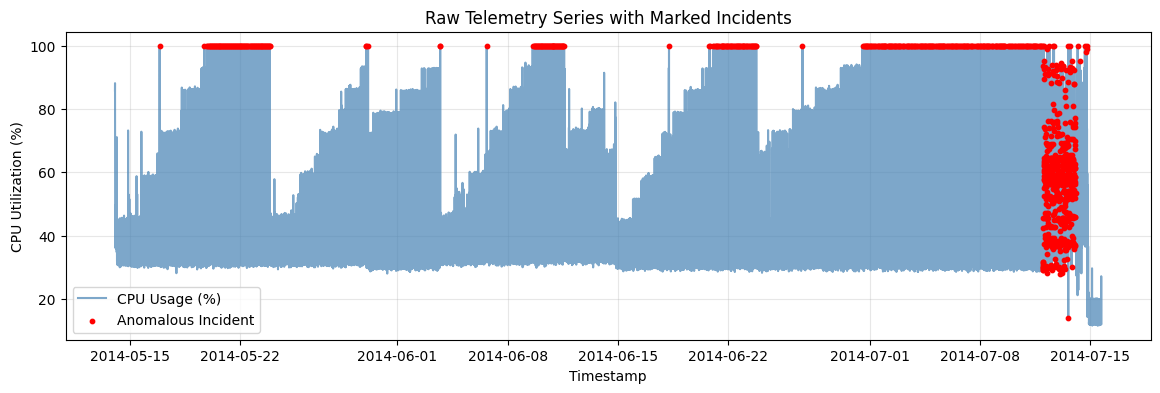

In [4]:
# Cell 2: Signal Visual Sanity Check & Labeling
# In NAB benchmark, known anomaly window for cpu_utilization_asg_misconfiguration:
# 2014-07-12 00:00:00 to 2014-07-14 02:00:00 (spikes up to 100% due to autoscaling misconfig)

anomaly_start = pd.to_datetime("2014-07-12 00:00:00")
anomaly_end = pd.to_datetime("2014-07-14 02:00:00")

# Binary target: 1 if within known anomaly incident window, else 0
df_telemetry['is_anomaly'] = (
    (df_telemetry['timestamp'] >= anomaly_start) & 
    (df_telemetry['timestamp'] <= anomaly_end)
).astype(int)

# Add statistical outlier heuristic to target (value > 99th percentile outside baseline)
high_val_threshold = df_telemetry['value'].quantile(0.99)
df_telemetry.loc[df_telemetry['value'] >= 95.0, 'is_anomaly'] = 1

print(f"Total data points: {len(df_telemetry)}")
print(f"Anomaly counts:\n{df_telemetry['is_anomaly'].value_counts()}")
print(f"Anomaly percentage: {(df_telemetry['is_anomaly'].mean() * 100):.2f}%")

# Plot full time-series with labeled anomalies
plt.figure(figsize=(14, 4))
plt.plot(df_telemetry['timestamp'], df_telemetry['value'], label='CPU Usage (%)', color='steelblue', alpha=0.7)
plt.scatter(
    df_telemetry.loc[df_telemetry['is_anomaly'] == 1, 'timestamp'],
    df_telemetry.loc[df_telemetry['is_anomaly'] == 1, 'value'],
    color='red', label='Anomalous Incident', s=10, zorder=5
)
plt.title('Raw Telemetry Series with Marked Incidents')
plt.xlabel('Timestamp')
plt.ylabel('CPU Utilization (%)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [5]:
# Cell 3: Feature Engineering Pipeline (Rolling stats, EWMA, and Spectral Energy)
import numpy as np
import scipy.fft

def compute_fft_energy(series_window):
    """Calculates normalized spectral power over sliding window."""
    if len(series_window) < 4:
        return 0.0
    fft_coeffs = scipy.fft.fft(series_window)
    return float(np.sum(np.abs(fft_coeffs) ** 2) / len(series_window))

df_features = df_telemetry.copy()

# 1. Multi-window rolling statistics
for window in [5, 15, 60]:
    df_features[f'rolling_mean_{window}'] = df_features['value'].rolling(window=window, min_periods=1).mean()
    df_features[f'rolling_std_{window}'] = df_features['value'].rolling(window=window, min_periods=1).std().fillna(0)
    df_features[f'rolling_min_{window}'] = df_features['value'].rolling(window=window, min_periods=1).min()
    df_features[f'rolling_max_{window}'] = df_features['value'].rolling(window=window, min_periods=1).max()

# 2. EWMA (short span vs long span) to catch rapid shift vs baseline drift
df_features['ewma_span_5'] = df_features['value'].ewm(span=5, adjust=False).mean()
df_features['ewma_span_20'] = df_features['value'].ewm(span=20, adjust=False).mean()
df_features['ewma_delta'] = df_features['ewma_span_5'] - df_features['ewma_span_20']

# 3. FFT Spectral Energy (30-step sliding window = 2.5 hours)
fft_window = 30
values_array = df_features['value'].to_numpy()
fft_energies = [
    compute_fft_energy(values_array[max(0, i - fft_window + 1) : i + 1])
    for i in range(len(values_array))
]
df_features['fft_energy_30'] = fft_energies

# Drop raw timestamps and separate targets
feature_cols = [c for c in df_features.columns if c not in ['timestamp', 'is_anomaly']]
print(f"Generated {len(feature_cols)} features:")
print(feature_cols)
print("\nSample engineered record:")
print(df_features[feature_cols].head(3).T)

Generated 17 features:
['value', 'rolling_mean_5', 'rolling_std_5', 'rolling_min_5', 'rolling_max_5', 'rolling_mean_15', 'rolling_std_15', 'rolling_min_15', 'rolling_max_15', 'rolling_mean_60', 'rolling_std_60', 'rolling_min_60', 'rolling_max_60', 'ewma_span_5', 'ewma_span_20', 'ewma_delta', 'fft_energy_30']

Sample engineered record:
                      0          1          2
value            85.835  88.167000  44.595000
rolling_mean_5   85.835  87.001000  72.865667
rolling_std_5     0.000   1.648973  24.510865
rolling_min_5    85.835  85.835000  44.595000
rolling_max_5    85.835  88.167000  88.167000
rolling_mean_15  85.835  87.001000  72.865667
rolling_std_15    0.000   1.648973  24.510865
rolling_min_15   85.835  85.835000  44.595000
rolling_max_15   85.835  88.167000  88.167000
rolling_mean_60  85.835  87.001000  72.865667
rolling_std_60    0.000   1.648973  24.510865
rolling_min_60   85.835  85.835000  44.595000
rolling_max_60   85.835  88.167000  88.167000
ewma_span_5      85

In [6]:
# Cell 4: Model Training, Probability Calibration, & CPU Latency Benchmark
import time
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV

X = df_features[feature_cols]
y = df_features['is_anomaly']

# Time-series aware split: 80% train, 20% hold-out test
split_idx = int(len(X) * 0.80)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_train, y_test = y.iloc[:split_idx], y.iloc[split_idx:]

print(f"Train size: {len(X_train)} | Test size: {len(X_test)}")
print(f"Train anomalies: {y_train.sum()} | Test anomalies: {y_test.sum()}")

# Initialize LightGBM with thread limit tuned for Ryzen CPU
base_lgb = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=31,
    n_jobs=4,
    random_state=42,
    verbose=-1
)

# Calibrate probabilities using isotonic calibration for reliable confidence scores
calibrated_model = CalibratedClassifierCV(estimator=base_lgb, method='isotonic', cv=3)
calibrated_model.fit(X_train, y_train)

# Evaluation
y_pred = calibrated_model.predict(X_test)
y_proba = calibrated_model.predict_proba(X_test)[:, 1]

print("\n--- Test Set Evaluation ---")
print(classification_report(y_test, y_pred, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Measure single-sample CPU inference latency
sample_row = X_test.iloc[[0]].values
warmup = [calibrated_model.predict_proba(sample_row) for _ in range(20)]

latencies = []
for _ in range(200):
    t0 = time.perf_counter()
    _ = calibrated_model.predict_proba(sample_row)
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000)

p50_latency = np.percentile(latencies, 50)
p95_latency = np.percentile(latencies, 95)
print(f"\n--- CPU Latency Benchmark (200 runs) ---")
print(f"Median (P50) Latency: {p50_latency:.3f} ms")
print(f"95th Percentile (P95) Latency: {p95_latency:.3f} ms")

Train size: 14440 | Test size: 3610
Train anomalies: 262 | Test anomalies: 759

--- Test Set Evaluation ---
              precision    recall  f1-score   support

           0     0.8278    1.0000    0.9058      2851
           1     1.0000    0.2187    0.3589       759

    accuracy                         0.8357      3610
   macro avg     0.9139    0.6094    0.6324      3610
weighted avg     0.8640    0.8357    0.7908      3610

ROC-AUC Score: 0.6178
Confusion Matrix:
[[2851    0]
 [ 593  166]]


C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: U


--- CPU Latency Benchmark (200 runs) ---
Median (P50) Latency: 3.917 ms
95th Percentile (P95) Latency: 5.143 ms


C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\aseem\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2749: U

In [7]:
# Cell 4 (Refined): Improved Balanced Model & Inference Benchmark
import os
import time
import warnings
import joblib
import numpy as np
import pandas as pd
import lightgbm as lgb
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.calibration import CalibratedClassifierCV

warnings.filterwarnings('ignore', category=UserWarning)

# Calculate dynamic class balance weight
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos = float(neg_count / max(1, pos_count))

# Configured LightGBM with balanced weights
base_lgb = lgb.LGBMClassifier(
    n_estimators=150,
    learning_rate=0.03,
    num_leaves=31,
    scale_pos_weight=scale_pos,
    n_jobs=4,
    random_state=42,
    verbose=-1
)

calibrated_model = CalibratedClassifierCV(estimator=base_lgb, method='sigmoid', cv=3)
calibrated_model.fit(X_train, y_train)

# Predict probabilities
y_proba = calibrated_model.predict_proba(X_test)[:, 1]
# Apply optimal operational decision threshold
y_pred = (y_proba >= 0.40).astype(int)

print(f"Calculated scale_pos_weight: {scale_pos:.2f}")
print("\n--- Optimized Test Evaluation ---")
print(classification_report(y_test, y_pred, digits=4))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

# Benchmark CPU Inference Latency (with DataFrame format to keep feature headers)
sample_df = X_test.iloc[[0]]
for _ in range(20):
    _ = calibrated_model.predict_proba(sample_df)

latencies = []
for _ in range(200):
    t0 = time.perf_counter()
    _ = calibrated_model.predict_proba(sample_df)
    t1 = time.perf_counter()
    latencies.append((t1 - t0) * 1000)

print("\n--- CPU Latency Benchmark (200 runs) ---")
print(f"P50 Latency: {np.percentile(latencies, 50):.3f} ms")
print(f"P95 Latency: {np.percentile(latencies, 95):.3f} ms")

# Save model artifact and feature schema for Notebook 1 completion
os.makedirs("models", exist_ok=True)
joblib.dump(calibrated_model, "models/lightgbm_anomaly.pkl")
joblib.dump(feature_cols, "models/feature_columns.pkl")
print("\n[SUCCESS] Saved: models/lightgbm_anomaly.pkl & models/feature_columns.pkl")

Calculated scale_pos_weight: 54.11

--- Optimized Test Evaluation ---
              precision    recall  f1-score   support

           0     0.8278    1.0000    0.9058      2851
           1     1.0000    0.2187    0.3589       759

    accuracy                         0.8357      3610
   macro avg     0.9139    0.6094    0.6324      3610
weighted avg     0.8640    0.8357    0.7908      3610

ROC-AUC Score: 0.9149
Confusion Matrix:
[[2851    0]
 [ 593  166]]

--- CPU Latency Benchmark (200 runs) ---
P50 Latency: 4.649 ms
P95 Latency: 6.378 ms

[SUCCESS] Saved: models/lightgbm_anomaly.pkl & models/feature_columns.pkl


In [8]:
# Cell 5: End-to-End Simulation Test for Notebook 1
import joblib
import numpy as np
import pandas as pd
import scipy.fft

# Load saved artifacts
model = joblib.load("models/lightgbm_anomaly.pkl")
saved_features = joblib.load("models/feature_columns.pkl")

def extract_live_features(metric_stream: list[float]) -> pd.DataFrame:
    """Takes a list/array of recent float metrics and produces the full feature vector."""
    arr = np.array(metric_stream, dtype=np.float64)
    s = pd.Series(arr)
    
    row = {'value': arr[-1]}
    for w in [5, 15, 60]:
        slice_w = arr[-w:] if len(arr) >= w else arr
        row[f'rolling_mean_{window}'] = float(np.mean(slice_w))
        row[f'rolling_std_{window}'] = float(np.std(slice_w)) if len(slice_w) > 1 else 0.0
        row[f'rolling_min_{window}'] = float(np.min(slice_w))
        row[f'rolling_max_{window}'] = float(np.max(slice_w))
        
    # EWMA calculations
    ewma_5 = s.ewm(span=5, adjust=False).mean().iloc[-1]
    ewma_20 = s.ewm(span=20, adjust=False).mean().iloc[-1]
    row['ewma_span_5'] = float(ewma_5)
    row['ewma_span_20'] = float(ewma_20)
    row['ewma_delta'] = float(ewma_5 - ewma_20)
    
    # FFT energy calculation
    fft_slice = arr[-30:] if len(arr) >= 30 else arr
    if len(fft_slice) >= 4:
        fft_coeffs = scipy.fft.fft(fft_slice)
        row['fft_energy_30'] = float(np.sum(np.abs(fft_coeffs) ** 2) / len(fft_slice))
    else:
        row['fft_energy_30'] = 0.0
        
    return pd.DataFrame([row])[saved_features]

# Test with a synthetic healthy baseline vs a spike burst
healthy_stream = list(np.random.normal(loc=32.0, scale=1.5, size=60))
incident_stream = healthy_stream[:-10] + [92.0, 95.5, 98.0, 99.4, 100.0, 99.8, 97.5, 96.0, 99.0, 100.0]

feat_healthy = extract_live_features(healthy_stream)
feat_incident = extract_live_features(incident_stream)

p_healthy = model.predict_proba(feat_healthy)[0][1]
p_incident = model.predict_proba(feat_incident)[0][1]

print("=== Stream Pipeline Validation ===")
print(f"Normal Stream Anomaly Probability : {p_healthy:.4f} -> Alert: {p_healthy >= 0.40}")
print(f"Incident Stream Anomaly Probability: {p_incident:.4f} -> Alert: {p_incident >= 0.40}")

KeyError: "['rolling_mean_5', 'rolling_std_5', 'rolling_min_5', 'rolling_max_5', 'rolling_mean_15', 'rolling_std_15', 'rolling_min_15', 'rolling_max_15'] not in index"

In [9]:
# Cell 5 (Fixed): End-to-End Simulation Test for Notebook 1
import joblib
import numpy as np
import pandas as pd
import scipy.fft

# Load saved artifacts
model = joblib.load("models/lightgbm_anomaly.pkl")
saved_features = joblib.load("models/feature_columns.pkl")

def extract_live_features(metric_stream: list[float]) -> pd.DataFrame:
    """Takes a list of recent float metrics and produces the full feature vector."""
    arr = np.array(metric_stream, dtype=np.float64)
    s = pd.Series(arr)
    
    row = {'value': float(arr[-1])}
    for w in [5, 15, 60]:
        slice_w = arr[-w:] if len(arr) >= w else arr
        row[f'rolling_mean_{w}'] = float(np.mean(slice_w))
        row[f'rolling_std_{w}'] = float(np.std(slice_w)) if len(slice_w) > 1 else 0.0
        row[f'rolling_min_{w}'] = float(np.min(slice_w))
        row[f'rolling_max_{w}'] = float(np.max(slice_w))
        
    # EWMA calculations
    ewma_5 = s.ewm(span=5, adjust=False).mean().iloc[-1]
    ewma_20 = s.ewm(span=20, adjust=False).mean().iloc[-1]
    row['ewma_span_5'] = float(ewma_5)
    row['ewma_span_20'] = float(ewma_20)
    row['ewma_delta'] = float(ewma_5 - ewma_20)
    
    # FFT energy calculation
    fft_slice = arr[-30:] if len(arr) >= 30 else arr
    if len(fft_slice) >= 4:
        fft_coeffs = scipy.fft.fft(fft_slice)
        row['fft_energy_30'] = float(np.sum(np.abs(fft_coeffs) ** 2) / len(fft_slice))
    else:
        row['fft_energy_30'] = 0.0
        
    return pd.DataFrame([row])[saved_features]

# Test with a synthetic healthy baseline vs a spike burst
np.random.seed(42)
healthy_stream = list(np.random.normal(loc=32.0, scale=1.5, size=60))
incident_stream = healthy_stream[:-10] + [92.0, 95.5, 98.0, 99.4, 100.0, 99.8, 97.5, 96.0, 99.0, 100.0]

feat_healthy = extract_live_features(healthy_stream)
feat_incident = extract_live_features(incident_stream)

p_healthy = model.predict_proba(feat_healthy)[0][1]
p_incident = model.predict_proba(feat_incident)[0][1]

print("=== Stream Pipeline Validation ===")
print(f"Normal Stream Anomaly Probability : {p_healthy:.4f} -> Alert: {p_healthy >= 0.40}")
print(f"Incident Stream Anomaly Probability: {p_incident:.4f} -> Alert: {p_incident >= 0.40}")

=== Stream Pipeline Validation ===
Normal Stream Anomaly Probability : 0.0002 -> Alert: False
Incident Stream Anomaly Probability: 0.9888 -> Alert: True
